# Peak-density sub-cube test

Finds the highest-density cell, builds a sub-cube of 0.1 × box side centred on it,
and runs all four variants at lcube = 8, 9, 10.

This notebook tests the OOB-boundary fix in the coarse cell path.

**Run from `multiamr2cube_optim/`.**

In [1]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt
import time
from configparser import ConfigParser

BASE_DIR   = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'claude' else os.getcwd()
CLAUDE_DIR = os.path.join(BASE_DIR, 'claude')
sys.path.insert(0, BASE_DIR)
sys.path.insert(0, CLAUDE_DIR)

import pyablo
import multiamr2cube_ref              as m_ref
import multiamr2cube_numpy            as m_numpy
import multiamr2cube_numba            as m_numba
import multiamr2cube_numba_full       as m_numba_full
from multiamr2cube_ref_prefilter import prefilter

print('BASE_DIR:', BASE_DIR)

BASE_DIR: /Users/pedro/work/simus/dyablo/dyablo/multiamr2cube_optim


## 1 — Load snapshot

In [2]:
PATH       = BASE_DIR + '/'
SNAPNAME   = 'star'
CONFIGNAME = 'restart_star_279982.ini'
T          = 70000
FIELD      = 'rho'

config = ConfigParser(inline_comment_prefixes=('#', ';'))
config.read(PATH + CONFIGNAME)

reader = pyablo.XdmfReader()
snap   = reader.readSnapshot(PATH + SNAPNAME + '_iter{:07d}.xmf'.format(T))

cc, lcell, Lbox = m_ref.extract_snapshot_data(snap, config)
values = np.array(snap.readAllFloat(FIELD), dtype=np.float64)

lmin = int(lcell.min())
lmax = int(lcell.max())
print('%d cells | lmin=%d lmax=%d | Lbox=%s' % (len(values), lmin, lmax, Lbox))

27825344 cells | lmin=8 lmax=10 | Lbox=[1.84219576e+23 1.84219576e+23 1.84219576e+23]


## 2 — Find peak-density location and build extent

In [3]:
peak_idx = np.argmax(values)
peak_cc  = cc[peak_idx]
peak_val = values[peak_idx]
print('Peak rho = %.4e  at cell centre (%.6f, %.6f, %.6f)' % (peak_val, peak_cc[0], peak_cc[1], peak_cc[2]))

# sub-cube half-width = 0.05 * Lbox (so full width = 0.1 * Lbox)
hw = 0.05 * np.array(Lbox)

# fractional extent (clipped to [0,1] so we don't go outside the box)
x0 = max(0.0, (peak_cc[0] - hw[0]) / Lbox[0])
x1 = min(1.0, (peak_cc[0] + hw[0]) / Lbox[0])
y0 = max(0.0, (peak_cc[1] - hw[1]) / Lbox[1])
y1 = min(1.0, (peak_cc[1] + hw[1]) / Lbox[1])
z0 = max(0.0, (peak_cc[2] - hw[2]) / Lbox[2])
z1 = min(1.0, (peak_cc[2] + hw[2]) / Lbox[2])

EXTENT = [x0, x1, y0, y1, z0, z1]
print('Extent: [%.6f, %.6f, %.6f, %.6f, %.6f, %.6f]' % tuple(EXTENT))
print('Physical size: %.4f x %.4f x %.4f' % ((x1-x0)*Lbox[0], (y1-y0)*Lbox[1], (z1-z0)*Lbox[2]))

Peak rho = 1.7777e-22  at cell centre (40208081176319303352320.000000, 13942399513041370611712.000000, 123862478254567539605504.000000)
Extent: [0.168262, 0.268262, 0.025684, 0.125684, 0.622363, 0.722363]
Physical size: 18421957550134658072576.0000 x 18421957550134662266880.0000 x 18421957550134660169728.0000


## 3 — Pre-filter statistics

In [4]:
cc_f, lc_f, v_f = prefilter(cc, lcell, values, Lbox, EXTENT)
print('Total cells : %d' % len(values))
print('After filter: %d  (%.1f%%)' % (len(v_f), 100.0 * len(v_f) / len(values)))

Total cells : 27825344
After filter: 206344  (0.7%)


## 4 — Warm up numba

In [5]:
print('Compiling numba kernels...')
t0 = time.perf_counter()
m_numba.warmup(cc, lcell, values, Lbox)
m_numba_full.warmup(cc, lcell, values, Lbox)
print('  done in %.1fs' % (time.perf_counter() - t0))

Compiling numba kernels...
  done in 0.8s


## 5 — Benchmark: all variants at lcube = 8, 9, 10

All variants receive the **pre-filtered** arrays to put them on equal footing
(the pre-filter itself is not timed).

In [6]:
LCUBES    = [8, 9, 10]
N_REPEATS = 3

VARIANTS = {
    'ref':        m_ref.multiamr2cube,
    'numpy':      m_numpy.multiamr2cube,
    'numba':      m_numba.multiamr2cube,
    'numba_full': m_numba_full.multiamr2cube,
}

results = {}  # (name, lcube) -> {'times': [...], 'arr': ndarray}

for lcube in LCUBES:
    print('\n=== lcube=%d ===' % lcube)
    ref_arr = None
    for name, fn in VARIANTS.items():
        times = []
        for _ in range(N_REPEATS):
            t0  = time.perf_counter()
            arr = fn(cc_f, lc_f, v_f, Lbox, lcube, EXTENT)
            times.append(time.perf_counter() - t0)
        results[(name, lcube)] = {'times': times, 'arr': arr}
        t_med = np.median(times)
        if ref_arr is None:
            ref_arr = arr
            tag = 'REF  shape=%s' % str(arr.shape)
        else:
            mx = np.max(np.abs(ref_arr))
            rel = np.max(np.abs(arr - ref_arr)) / (mx + 1e-300)
            tag = ('OK  rel=%.1e' % rel) if rel < 1e-10 else ('FAIL rel=%.2e' % rel)
        print('  %-12s  median=%.3fs  %s' % (name, t_med, tag))


=== lcube=8 ===
  ref           median=0.007s  REF  shape=(26, 26, 26)
  numpy         median=0.006s  OK  rel=0.0e+00
  numba         median=0.005s  OK  rel=0.0e+00
  numba_full    median=0.001s  FAIL rel=2.79e+00

=== lcube=9 ===
  ref           median=0.047s  REF  shape=(51, 51, 51)
  numpy         median=0.005s  OK  rel=0.0e+00
  numba         median=0.005s  OK  rel=0.0e+00
  numba_full    median=0.002s  FAIL rel=1.27e+00

=== lcube=10 ===
  ref           median=0.626s  REF  shape=(102, 102, 102)
  numpy         median=0.014s  OK  rel=0.0e+00
  numba         median=0.005s  OK  rel=0.0e+00
  numba_full    median=0.010s  OK  rel=0.0e+00


## 6 — Timing plot

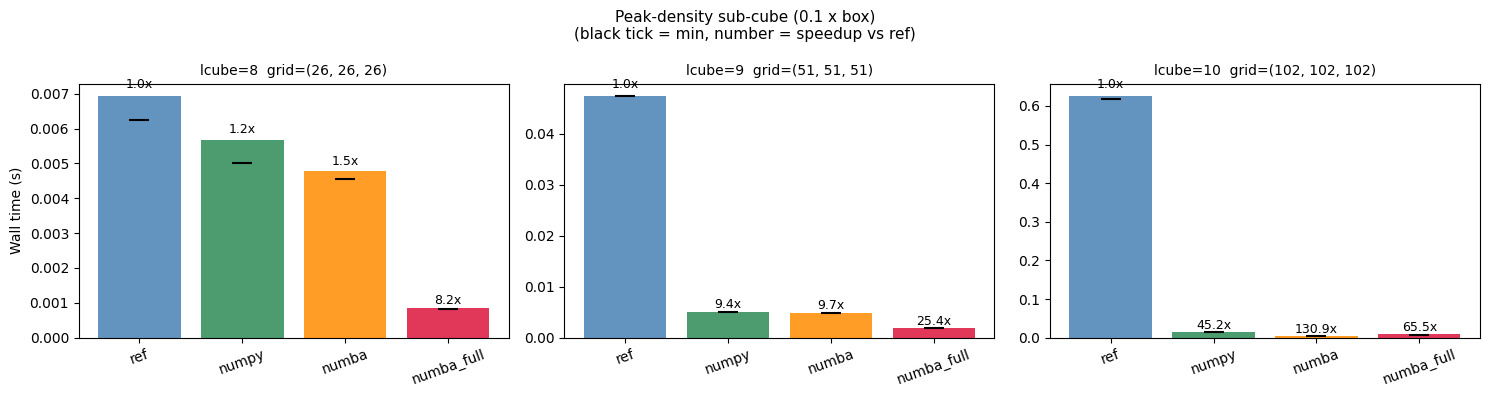

Saved timing_peak_subcube.png


In [7]:
variant_names = list(VARIANTS.keys())
colors = {'ref': 'steelblue', 'numpy': 'seagreen', 'numba': 'darkorange', 'numba_full': 'crimson'}

fig, axes = plt.subplots(1, len(LCUBES), figsize=(5 * len(LCUBES), 4), sharey=False)

for col, lcube in enumerate(LCUBES):
    ax = axes[col]
    medians = [np.median(results[(n, lcube)]['times']) for n in variant_names]
    mins    = [np.min(   results[(n, lcube)]['times']) for n in variant_names]
    ref_med = medians[0]
    bars = ax.bar(variant_names, medians,
                  color=[colors[n] for n in variant_names], alpha=0.85)
    ax.scatter(variant_names, mins, marker='_', s=200, color='black', zorder=5)
    for bar, med in zip(bars, medians):
        ax.text(bar.get_x() + bar.get_width()/2, med * 1.02,
                '%.1fx' % (ref_med / med), ha='center', va='bottom', fontsize=9)
    arr_shape = results[(variant_names[0], lcube)]['arr'].shape
    ax.set_title('lcube=%d  grid=%s' % (lcube, str(arr_shape)), fontsize=10)
    ax.set_ylabel('Wall time (s)' if col == 0 else '')
    ax.tick_params(axis='x', rotation=20)

plt.suptitle('Peak-density sub-cube (0.1 x box)\n(black tick = min, number = speedup vs ref)', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(CLAUDE_DIR, 'timing_peak_subcube.png'), dpi=150)
plt.show()
print('Saved timing_peak_subcube.png')

## 7 — Slice plots (numba_full, all lcubes)

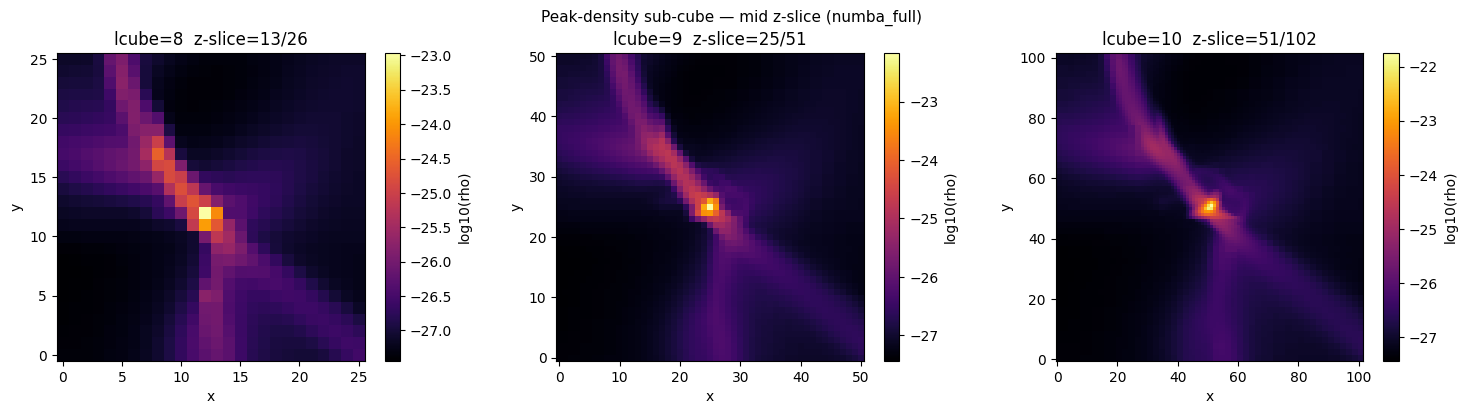

Saved slices_peak_subcube.png


In [8]:
fig, axes = plt.subplots(1, len(LCUBES), figsize=(5 * len(LCUBES), 4))

for col, lcube in enumerate(LCUBES):
    ax = axes[col]
    arr = results[('numba_full', lcube)]['arr']
    mid = arr.shape[2] // 2
    sl  = np.log10(arr[:, :, mid] + 1e-30)
    im  = ax.imshow(sl.T, origin='lower', aspect='equal', cmap='inferno')
    plt.colorbar(im, ax=ax, label='log10(rho)')
    ax.set_title('lcube=%d  z-slice=%d/%d' % (lcube, mid, arr.shape[2]))
    ax.set_xlabel('x'); ax.set_ylabel('y')

plt.suptitle('Peak-density sub-cube — mid z-slice (numba_full)', fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(CLAUDE_DIR, 'slices_peak_subcube.png'), dpi=150)
plt.show()
print('Saved slices_peak_subcube.png')